# Phase 2 — Model: build, train, evaluate, efficiency study

**Gate ("Done when")**: a chosen model saved to `model.keras`, a completed efficiency table,
a confusion matrix; test accuracy on letters typically **>90%**.

Workflow: train `baseline` and `separable` (MobileNetV2 optional), compare in TensorBoard,
evaluate the winner on the held-out test split, fill the efficiency table.

> The EMNIST **test split is used exactly once**, at the end, on final candidates —
> all tuning decisions are made on the **validation** split.

In [1]:
import sys, pathlib, json, time
sys.path.append(str(pathlib.Path.cwd().parent))

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from src.data import get_datasets, NUM_CLASSES
from src.model import (VARIANTS, compile_model, default_callbacks,
                       efficiency_row, measure_cpu_latency)

ARTIFACTS = pathlib.Path.cwd().parent / 'artifacts'
LOGS = pathlib.Path.cwd().parent / 'logs'
LOGS.mkdir(exist_ok=True)

tf.random.set_seed(42)
np.random.seed(42)

print("TF:", tf.__version__)
ds_train, ds_val, ds_test, info = get_datasets()

TF: 2.19.1


## 1. Validation

In [2]:
from src.data import check_split_integrity
check_split_integrity(ds_val, 'val')
check_split_integrity(ds_test, 'test')

val: 8880 examples, per-class min=306 max=376 -> all 26 classes present
test: 8880 examples, per-class min=307 max=366 -> all 26 classes present


array([320, 353, 341, 307, 352, 316, 325, 340, 335, 342, 342, 363, 344,
       342, 309, 356, 345, 366, 360, 353, 332, 343, 343, 360, 328, 363])

## 1. Inspect the architectures
`summary()` shows every layer and the parameter count. Both variants must be **well under 1M params**.
Note where the parameters live — almost all in the conv blocks, because GlobalAveragePooling keeps the head tiny.

In [3]:
from src.model import build_baseline, build_separable

m_base = build_baseline()
m_base.summary()
print()
m_sep = build_separable()
m_sep.summary()
print(f"\nparams: baseline={m_base.count_params():,}  separable={m_sep.count_params():,}")

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,210 (442.23 KB)

 Trainable params: 112,762 (440.48 KB)

 Non-trainable params: 448 (1.75 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 14, 14, 64)     │         2,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 7, 7, 128)      │         8,768 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,154 (125.60 KB)

 Trainable params: 31,706 (123.85 KB)

 Non-trainable params: 448 (1.75 KB)


params: baseline=113,210  separable=32,154


## 2. Train both variants
~30 epochs max with EarlyStopping(patience=5) — usually stops earlier.
On CPU expect roughly 1–3 min/epoch, so budget ~20–60 min for both runs (leave it running).

**TensorBoard**: each run logs to `ml/logs/<variant>`. In VS Code: Ctrl+Shift+P →
*"Python: Launch TensorBoard"* → pick the `ml/logs` folder. Watch `val_loss` and the
train/val accuracy gap live. To experiment later, change hyperparameters in the cell
below and use a **new run name** (e.g. `baseline_lr1e4`) so curves overlay in TensorBoard.

In [4]:
EPOCHS = 30
histories = {}
models = {}

for name in ['baseline', 'separable']:
    print(f"\n=== {name} ===")
    model = compile_model(VARIANTS[name](), lr=1e-3)
    cbs = default_callbacks(name, ARTIFACTS, LOGS)
    h = model.fit(ds_train, validation_data=ds_val, epochs=EPOCHS,
                  callbacks=cbs, verbose=2)
    histories[name] = h.history
    models[name] = model   # weights already restored to best epoch


=== baseline ===
Epoch 1/30
555/555 - 39s - 71ms/step - accuracy: 0.5751 - loss: 1.4140 - val_accuracy: 0.7342 - val_loss: 0.8014
Epoch 2/30
555/555 - 37s - 66ms/step - accuracy: 0.7972 - loss: 0.6447 - val_accuracy: 0.8900 - val_loss: 0.3363
Epoch 3/30
555/555 - 38s - 68ms/step - accuracy: 0.8406 - loss: 0.5013 - val_accuracy: 0.8846 - val_loss: 0.3514
Epoch 4/30
555/555 - 34s - 61ms/step - accuracy: 0.8615 - loss: 0.4350 - val_accuracy: 0.9105 - val_loss: 0.2657
Epoch 5/30
555/555 - 37s - 66ms/step - accuracy: 0.8755 - loss: 0.3897 - val_accuracy: 0.9150 - val_loss: 0.2495
Epoch 6/30
555/555 - 35s - 64ms/step - accuracy: 0.8838 - loss: 0.3601 - val_accuracy: 0.9145 - val_loss: 0.2407
Epoch 7/30
555/555 - 42s - 76ms/step - accuracy: 0.8901 - loss: 0.3402 - val_accuracy: 0.9289 - val_loss: 0.2044
Epoch 8/30
555/555 - 39s - 71ms/step - accuracy: 0.8939 - loss: 0.3250 - val_accuracy: 0.9278 - val_loss: 0.2066
Epoch 9/30
555/555 - 46s - 83ms/step - accuracy: 0.8989 - loss: 0.3094 - val_a

## 3. Training curves (quick matplotlib view; TensorBoard has the full picture)

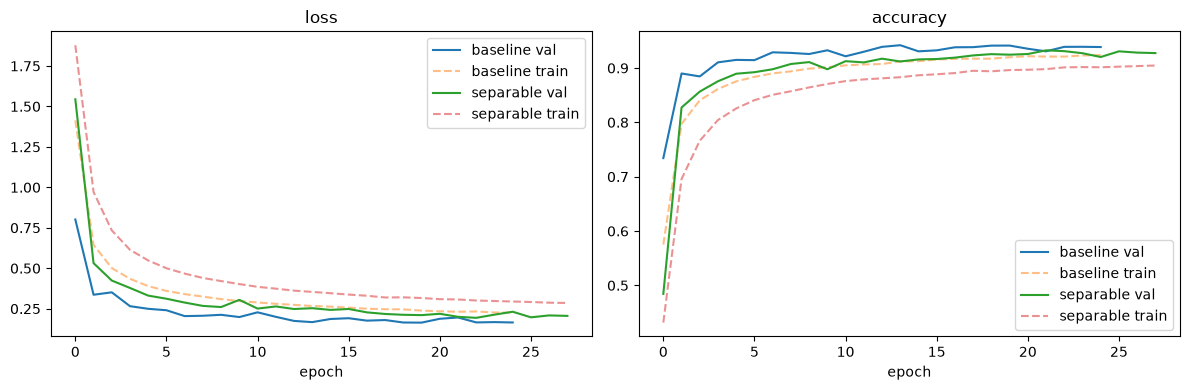

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    axes[0].plot(h['val_loss'], label=f'{name} val')
    axes[0].plot(h['loss'], '--', alpha=0.5, label=f'{name} train')
    axes[1].plot(h['val_accuracy'], label=f'{name} val')
    axes[1].plot(h['accuracy'], '--', alpha=0.5, label=f'{name} train')
axes[0].set_title('loss'); axes[1].set_title('accuracy')
for ax in axes: ax.legend(); ax.set_xlabel('epoch')
plt.tight_layout(); plt.show()

# Healthy signs: val curves flatten without diverging from train.
# A widening train/val gap = overfitting -> raise dropout or strengthen augmentation.

## 4. Final evaluation on the held-out test split
Both candidates are final, so evaluating both here is legitimate (no tuning follows).

In [6]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import string, seaborn as sns

letters = list(string.ascii_lowercase)
y_true = np.concatenate([y.numpy() for _, y in ds_test], axis=0)

results = {}
for name, model in models.items():
    y_pred = model.predict(ds_test, verbose=0).argmax(axis=1)
    acc = float((y_pred == y_true).mean())
    mf1 = float(f1_score(y_true, y_pred, average='macro'))
    results[name] = {'acc': acc, 'macro_f1': mf1, 'y_pred': y_pred}
    print(f"{name:10s}  test acc={acc:.4f}  macro-F1={mf1:.4f}")

baseline    test acc=0.9437  macro-F1=0.9438
separable   test acc=0.9340  macro-F1=0.9338


## 5. Confusion matrix (for the chosen variant)
Look for systematic pairs — classically **i/l, g/q, o/c** in EMNIST letters.
These will explain transcription errors later and belong in the report.

chosen variant: baseline


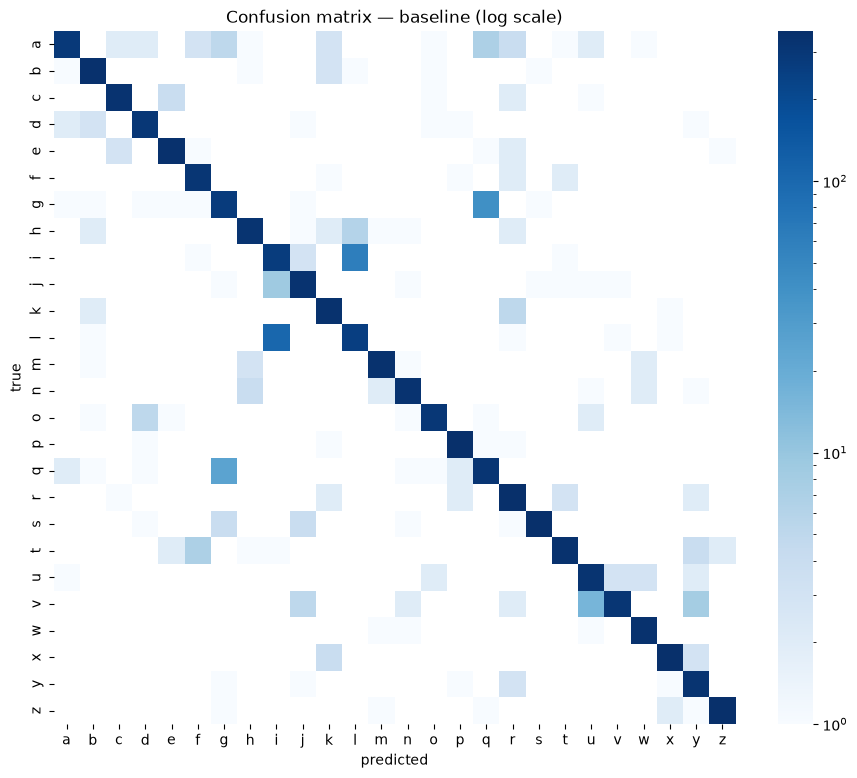

top confusions (true -> predicted, count):
  l -> i: 103
  i -> l: 61
  g -> q: 41
  q -> g: 25
  v -> u: 16
  j -> i: 9
  v -> y: 8
  a -> q: 7
  t -> f: 7
  h -> l: 6


In [7]:
CHOSEN = max(results, key=lambda k: results[k]['macro_f1'])
print("chosen variant:", CHOSEN)

cm = confusion_matrix(y_true, results[CHOSEN]['y_pred'])
plt.figure(figsize=(11, 9))
sns.heatmap(cm, cmap='Blues', xticklabels=letters, yticklabels=letters,
            norm=plt.matplotlib.colors.LogNorm())   # log scale exposes rare confusions
plt.xlabel('predicted'); plt.ylabel('true')
plt.title(f'Confusion matrix — {CHOSEN} (log scale)')
plt.savefig(ARTIFACTS / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# top confused pairs (off-diagonal)
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = np.dstack(np.unravel_index(np.argsort(cm_off, axis=None)[::-1], cm.shape))[0][:10]
print('top confusions (true -> predicted, count):')
for i, j in pairs:
    print(f"  {letters[i]} -> {letters[j]}: {cm_off[i, j]}")

In [8]:
print(classification_report(y_true, results[CHOSEN]['y_pred'],
                            target_names=letters, digits=3))

              precision    recall  f1-score   support

           a      0.976     0.900     0.937       320
           b      0.966     0.977     0.972       353
           c      0.982     0.977     0.979       341
           d      0.964     0.971     0.968       307
           e      0.977     0.977     0.977       352
           f      0.960     0.981     0.970       316
           g      0.882     0.852     0.867       325
           h      0.970     0.956     0.963       340
           i      0.704     0.803     0.750       335
           j      0.953     0.956     0.955       342
           k      0.954     0.977     0.965       342
           l      0.790     0.705     0.745       363
           m      0.985     0.980     0.983       344
           n      0.974     0.971     0.972       342
           o      0.977     0.964     0.971       309
           p      0.981     0.989     0.985       356
           q      0.857     0.904     0.880       345
           r      0.934    

## 6. Efficiency study table
Params / file size / accuracy / macro-F1 / mean CPU latency per image.
This table goes verbatim into the report (and is extended with the .tflite variants in Phase 3).

In [9]:
import pandas as pd

rows = []
for name, model in models.items():
    rows.append(efficiency_row(name, model, ARTIFACTS / f'{name}.keras',
                               results[name]['acc'], results[name]['macro_f1']))
eff = pd.DataFrame(rows)
print(eff.to_string(index=False))
eff.to_json(ARTIFACTS / 'efficiency_study.json', orient='records', indent=2)

  variant  params  size_kb  test_acc  macro_f1  cpu_latency_ms
 baseline  113210   1395.7    0.9437    0.9438           2.427
separable   32154    447.9    0.9340    0.9338           1.860


## 7. Promote the chosen model
Copies `<chosen>.keras` to the canonical `model.keras` that Phase 3 (quantization) expects.

In [10]:
import shutil
src = ARTIFACTS / f'{CHOSEN}.keras'
dst = ARTIFACTS / 'model.keras'
shutil.copyfile(src, dst)
json.dump({'chosen_variant': CHOSEN, **{k: v for k, v in results[CHOSEN].items() if k != 'y_pred'}},
          open(ARTIFACTS / 'chosen_model.json', 'w'), indent=2)
print('promoted', CHOSEN, '->', dst.name)

promoted baseline -> model.keras


## Gate checklist (Phase 2 "Done when")
- [X] Both variants trained; curves healthy (no runaway overfitting)
- [X] Test acc of chosen variant **>90%**, macro-F1 recorded
- [X] Confusion matrix saved (`confusion_matrix.png`), top confusions noted for the report
- [X] `efficiency_study.json` complete
- [X] `model.keras` = promoted chosen variant (Phase 3 input)
- [X] `git add -A && git commit -m "Phase 2: trained models + efficiency study"`